In [ ]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import tensorflow as tf

In [ ]:
def load_stock_data(ticker, start_date, end_date):
    data = yf.download(ticker, start=start_date, end=end_date, auto_adjust=True)
    if isinstance(data.columns, pd.MultiIndex):
        data.columns = data.columns.get_level_values(0)
    return data

ticker = "AAPL"
start_date = "2015-01-01"
end_date = "2025-01-01"

df = load_stock_data(ticker, start_date, end_date)

df.head()


[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Date,,,,,
2015-01-02,24.192606,24.659508,23.754470,24.648443,212818400
2015-01-05,23.511063,24.042136,23.325188,23.962475,257142000
2015-01-06,23.513275,23.772173,23.152587,23.575233,263188400
2015-01-07,23.842974,23.942549,23.610629,23.721269,160423600
2015-01-08,24.759085,24.816618,24.053199,24.170479,237458000


In [ ]:
df.head()
df.tail()
print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns)
print("\nData Types:")
print(df.dtypes)
print("\nMissing Values:")
print(df.isnull().sum())
df = df.dropna()
print("\nSummary Statistics:")
print(df.describe())


Dataset Shape: (2516, 5)

Columns:
Index(['Close', 'High', 'Low', 'Open', 'Volume'], dtype='object', name='Price')

Data Types:
Price
Close     float64
High      float64
Low       float64
Open      float64
Volume      int64
dtype: object

Missing Values:
Price
Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64

Summary Statistics:
Price        Close         High          Low         Open        Volume
count  2516.000000  2516.000000  2516.000000  2516.000000  2.516000e+03
mean     93.684878    94.594694    92.673090    93.598213  1.170853e+08
std      65.319932    65.912255    64.634535    65.239868  6.839614e+07
min      20.565870    20.868639    20.367816    20.488465  2.323470e+07
25%      35.157635    35.554809    34.780272    35.177804  7.105610e+07
50%      64.268616    64.822329    63.468147    64.109471  1.003646e+08
75%     149.955379   151.700187   147.992763   149.778489  1.426216e+08
max     257.375549   258.448710   255.994390   256.550832  6.488252e+

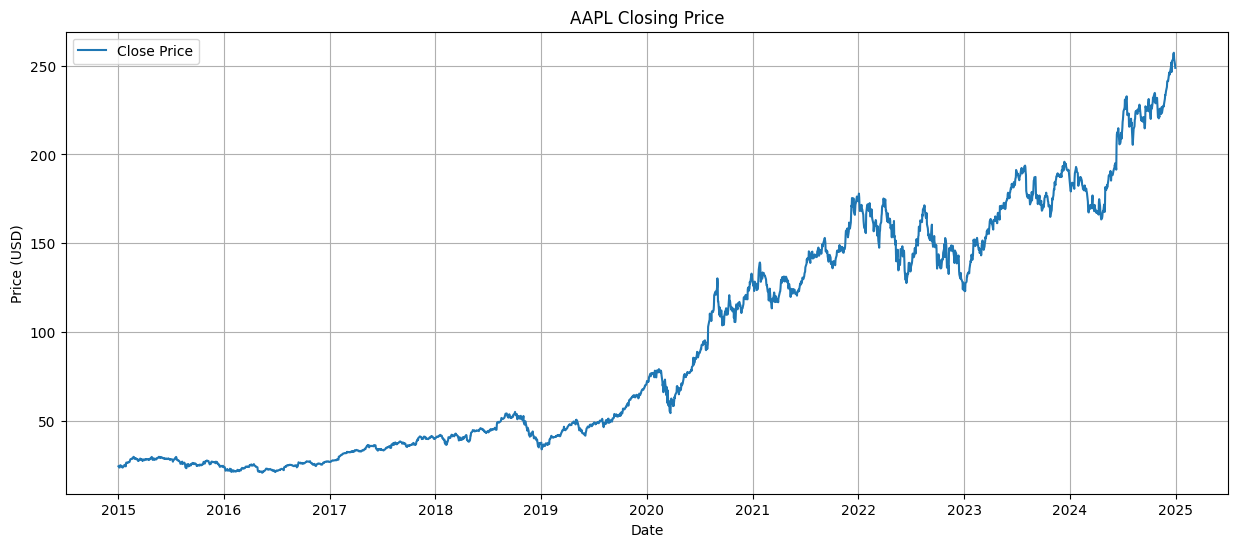

In [ ]:
plt.figure(figsize=(15, 6))
plt.plot(df.index, df["Close"], label="Close Price")
plt.title(f"{ticker} Closing Price")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
features = ["Open", "High", "Low", "Close", "Volume"]
data = df[features].copy()


data["Volume"] = np.log1p(data["Volume"])

scaler = MinMaxScaler(feature_range=(0, 1))


scaled_data = scaler.fit_transform(data)

close_scaler = MinMaxScaler(feature_range=(0, 1))
close_scaler.fit(data[["Close"]])

print("Scaled Data Shape:", scaled_data.shape)

print(scaled_data[:5])


Scaled Data Shape: (2516, 5)
[[0.01762237 0.01595617 0.01437297 0.01531498 0.6651994 ]
 [0.01471649 0.01335759 0.0125511  0.01243696 0.72202123]
 [0.01307607 0.01222128 0.01181858 0.0124463  0.72900172]
 [0.0136947  0.01293842 0.01376251 0.01383855 0.58031578]
 [0.01559763 0.01661747 0.01564078 0.01770711 0.69810254]]


In [ ]:
sequence_length = 60

X = []
y = []

for i in range(sequence_length, len(scaled_data)):
    X.append(scaled_data[i-sequence_length:i])
    y.append(scaled_data[i, 3])

X = np.array(X)
y = np.array(y)

print("Input Shape:", X.shape)
print("Target Shape:", y.shape)

Input Shape: (2456, 60, 5)
Target Shape: (2456,)


In [ ]:
train_size = int(len(X) * 0.8)

X_train = X[:train_size]
X_test = X[train_size:]

y_train = y[:train_size]
y_test = y[train_size:]

print("Training Input Shape:", X_train.shape)
print("Training Target Shape:", y_train.shape)

print("Testing Input Shape:", X_test.shape)
print("Testing Target Shape:", y_test.shape)

Training Input Shape: (1964, 60, 5)
Training Target Shape: (1964,)
Testing Input Shape: (492, 60, 5)
Testing Target Shape: (492,)


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam

model = Sequential()

model.add(LSTM(64, return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2])))
model.add(Dropout(0.2))

model.add(LSTM(32))
model.add(Dropout(0.2))

model.add(Dense(16, activation="relu"))
model.add(Dense(1))

model.compile(
    optimizer=Adam(learning_rate=0.001, clipnorm=1.0),
    loss="mse",
    metrics=["mae"]
)

model.summary()


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 64)         │        17,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,881 (120.63 KB)

 Trainable params: 30,881 (120.63 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=1e-6
)

history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.1,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)


Epoch 1/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 11s 65ms/step - loss: 0.0065 - mae: 0.0480 - val_loss: 7.9494e-04 - val_mae: 0.0237 - learning_rate: 0.0010
Epoch 2/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 51ms/step - loss: 0.0013 - mae: 0.0219 - val_loss: 0.0019 - val_mae: 0.0359 - learning_rate: 0.0010
Epoch 3/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 51ms/step - loss: 0.0010 - mae: 0.0201 - val_loss: 8.9709e-04 - val_mae: 0.0253 - learning_rate: 0.0010
Epoch 4/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 51ms/step - loss: 0.0011 - mae: 0.0205 - val_loss: 0.0010 - val_mae: 0.0261 - learning_rate: 0.0010
Epoch 5/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 72ms/step - loss: 8.8442e-04 - mae: 0.0182 - val_loss: 0.0014 - val_mae: 0.0306 - learning_rate: 0.0010
Epoch 6/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 53ms/step - loss: 8.1165e-04 - mae: 0.0178 - val_loss: 0.0010 - val_mae: 0.0265 - learning_rate: 0.0010
Epoch 7/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 52ms/step - loss: 6.5196e-04 - mae: 0.0161 - val_loss: 8.9546e-04 - val_mae: 0.0246 - lea

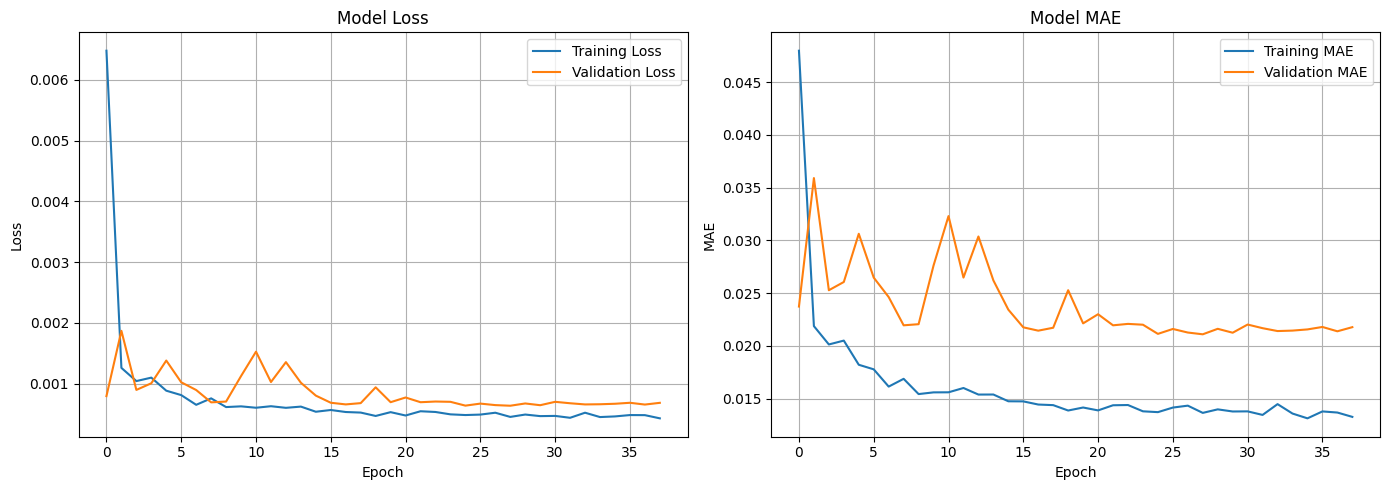

In [ ]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["mae"], label="Training MAE")
plt.plot(history.history["val_mae"], label="Validation MAE")
plt.title("Model MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
y_pred = model.predict(X_test)

print("Prediction Shape:", y_pred.shape)

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step
Prediction Shape: (492, 1)


In [ ]:
y_pred_actual = close_scaler.inverse_transform(y_pred.reshape(-1, 1)).flatten()
y_test_actual = close_scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()


In [ ]:
rmse = np.sqrt(mean_squared_error(y_test_actual, y_pred_actual))
mae = mean_absolute_error(y_test_actual, y_pred_actual)
r2 = r2_score(y_test_actual, y_pred_actual)

print(f"RMSE : {rmse:.2f}")
print(f"MAE  : {mae:.2f}")
print(f"R²   : {r2:.4f}")

RMSE : 11.89
MAE  : 9.59
R²   : 0.8058


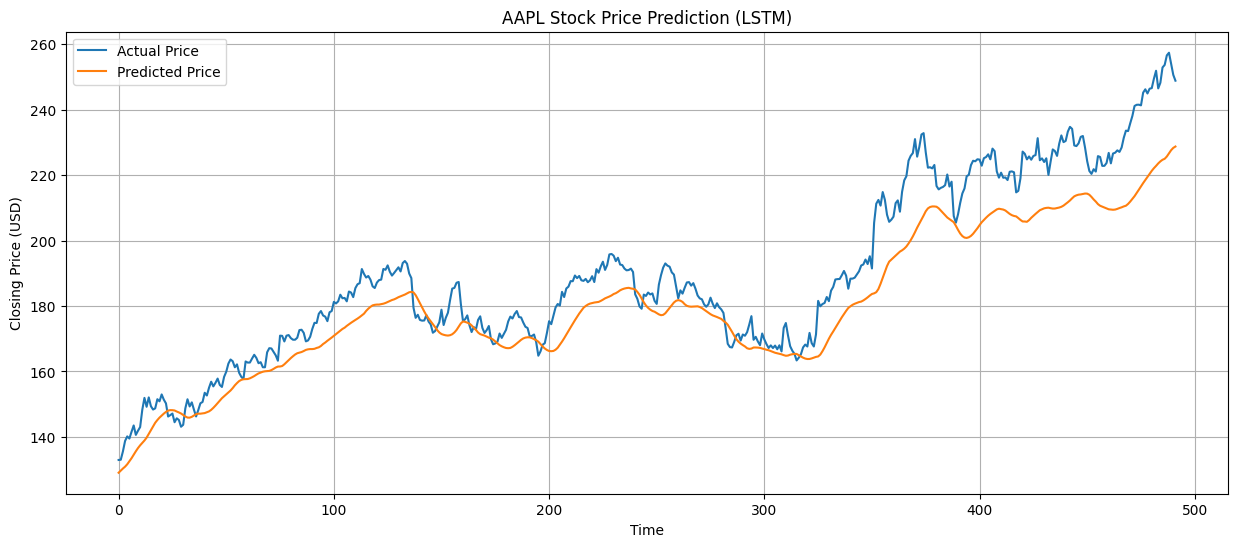

In [ ]:
plt.figure(figsize=(15, 6))

plt.plot(y_test_actual, label="Actual Price")
plt.plot(y_pred_actual, label="Predicted Price")

plt.title(f"{ticker} Stock Price Prediction (LSTM)")
plt.xlabel("Time")
plt.ylabel("Closing Price (USD)")

plt.legend()
plt.grid(True)

plt.show()

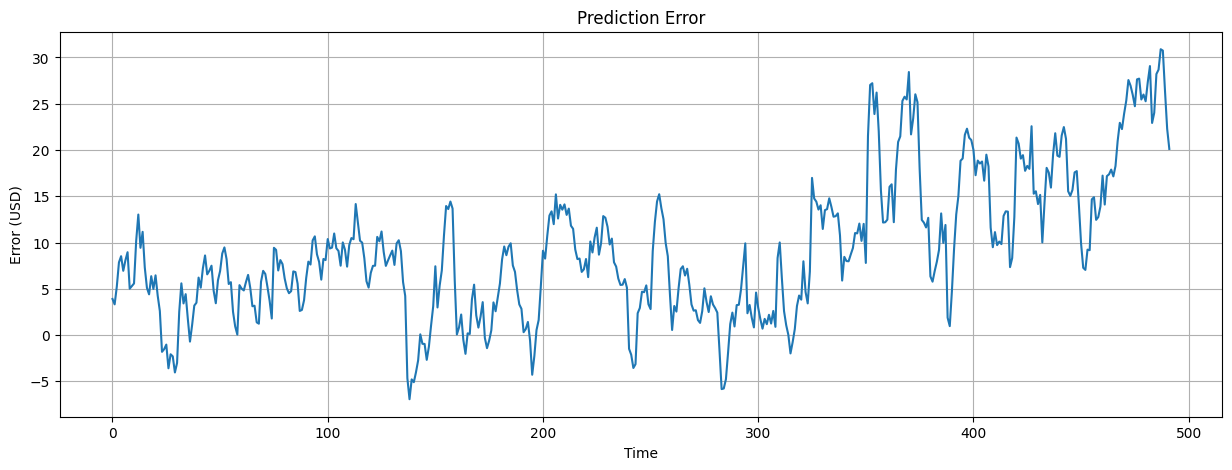

In [ ]:
errors = y_test_actual - y_pred_actual

plt.figure(figsize=(15, 5))

plt.plot(errors)

plt.title("Prediction Error")
plt.xlabel("Time")
plt.ylabel("Error (USD)")

plt.grid(True)

plt.show()

In [ ]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    Dense,
    Dropout,
    LayerNormalization,
    MultiHeadAttention,
    GlobalAveragePooling1D
)

In [ ]:
class PositionalEncoding(tf.keras.layers.Layer):

    def __init__(self, sequence_length, d_model):
        super().__init__()

        position = np.arange(sequence_length)[:, np.newaxis]
        dimension = np.arange(d_model)[np.newaxis, :]

        angle_rates = 1 / np.power(10000, (2 * (dimension // 2)) / np.float32(d_model))
        angle_rads = position * angle_rates

        angle_rads[:, 0::2] = np.sin(angle_rads[:, 0::2])
        angle_rads[:, 1::2] = np.cos(angle_rads[:, 1::2])

        self.positional_encoding = tf.cast(angle_rads[np.newaxis, ...], dtype=tf.float32)

    def call(self, inputs):
        return inputs + self.positional_encoding

In [ ]:
class TransformerEncoder(tf.keras.layers.Layer):

    def __init__(self, d_model, num_heads, ff_dim, dropout_rate=0.1):
        super().__init__()

        self.attention = MultiHeadAttention(
        num_heads=num_heads,
        key_dim=d_model // num_heads
    )

        self.ffn = tf.keras.Sequential([
            Dense(ff_dim, activation="relu"),
            Dense(d_model)
        ])

        self.norm1 = LayerNormalization(epsilon=1e-6)
        self.norm2 = LayerNormalization(epsilon=1e-6)

        self.dropout1 = Dropout(dropout_rate)
        self.dropout2 = Dropout(dropout_rate)

    def call(self, inputs, training=False):

        attention_output = self.attention(
            inputs,
            inputs
        )

        attention_output = self.dropout1(
            attention_output,
            training=training
        )

        out1 = self.norm1(
            inputs + attention_output
        )

        ffn_output = self.ffn(out1)

        ffn_output = self.dropout2(
            ffn_output,
            training=training
        )

        output = self.norm2(
            out1 + ffn_output
        )

        return output

In [ ]:
d_model = 64
num_heads = 4
ff_dim = 128
dropout_rate = 0.1
num_encoder_blocks = 2

inputs = Input(shape=(X_train.shape[1], X_train.shape[2]))

x = Dense(d_model)(inputs)

x = PositionalEncoding(
    sequence_length=X_train.shape[1],
    d_model=d_model
)(x)

for _ in range(num_encoder_blocks):
    x = TransformerEncoder(
        d_model=d_model,
        num_heads=num_heads,
        ff_dim=ff_dim,
        dropout_rate=dropout_rate
    )(x)

x = GlobalAveragePooling1D()(x)

dense_units = 32
x = Dense(dense_units, activation="relu")(x)

outputs = Dense(1)(x)

transformer_model = Model(inputs=inputs, outputs=outputs)

transformer_model.compile(
    optimizer=Adam(learning_rate=0.001, clipnorm=1.0),
    loss="mse",
    metrics=["mae"]
)

transformer_model.summary()


Model: "functional_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 60, 5)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 60, 64)         │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ positional_encoding             │ (None, 60, 64)         │             0 │
│ (PositionalEncoding)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_encoder             │ (None, 60, 64)         │        33,472 │
│ (TransformerEncoder)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_encoder_1           │ (None, 60, 64)         │        33,472 │
│ (TransformerEncoder)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 69,441 (271.25 KB)

 Trainable params: 69,441 (271.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=1e-6
)

transformer_history = transformer_model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.1,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)


Epoch 1/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 15s 127ms/step - loss: 0.0711 - mae: 0.1444 - val_loss: 0.0087 - val_mae: 0.0842 - learning_rate: 0.0010
Epoch 2/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 10s 122ms/step - loss: 0.0021 - mae: 0.0364 - val_loss: 0.0102 - val_mae: 0.0918 - learning_rate: 0.0010
Epoch 3/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 9s 96ms/step - loss: 0.0018 - mae: 0.0334 - val_loss: 0.0048 - val_mae: 0.0614 - learning_rate: 0.0010
Epoch 4/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 10s 97ms/step - loss: 0.0019 - mae: 0.0341 - val_loss: 0.0111 - val_mae: 0.0961 - learning_rate: 0.0010
Epoch 5/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 7s 123ms/step - loss: 0.0016 - mae: 0.0316 - val_loss: 0.0131 - val_mae: 0.1059 - learning_rate: 0.0010
Epoch 6/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 96ms/step - loss: 0.0019 - mae: 0.0340 - val_loss: 0.0061 - val_mae: 0.0701 - learning_rate: 0.0010
Epoch 7/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 10s 97ms/step - loss: 0.0022 - mae: 0.0370 - val_loss: 0.0033 - val_mae: 0.0498 - learning_rate: 0.0010

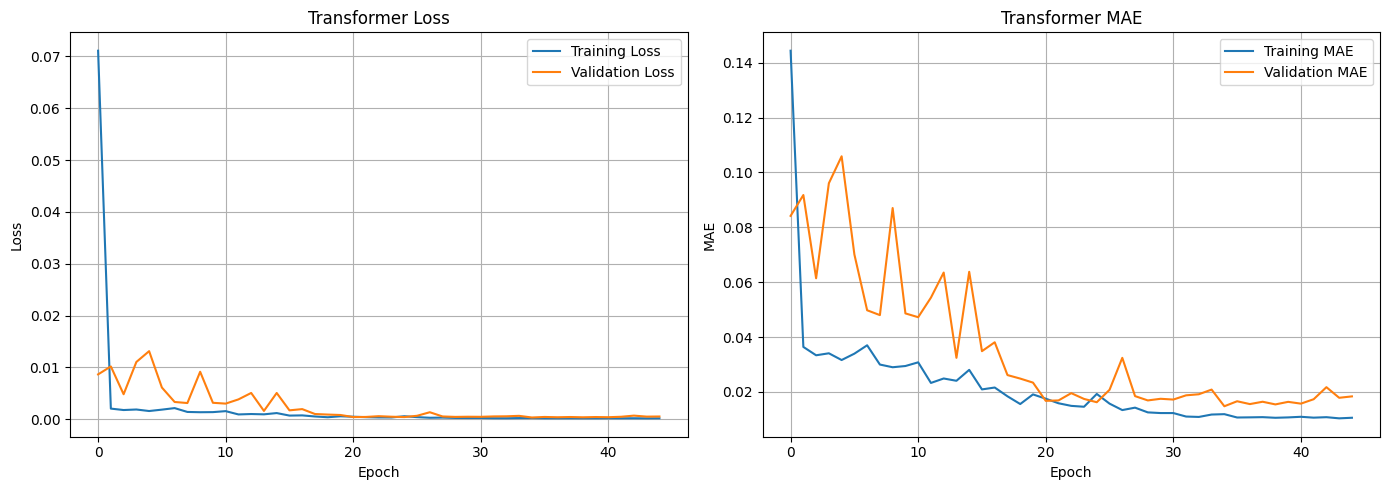

In [ ]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(transformer_history.history["loss"], label="Training Loss")
plt.plot(transformer_history.history["val_loss"], label="Validation Loss")
plt.title("Transformer Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(transformer_history.history["mae"], label="Training MAE")
plt.plot(transformer_history.history["val_mae"], label="Validation MAE")
plt.title("Transformer MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
transformer_pred = transformer_model.predict(X_test)

print("Prediction Shape:", transformer_pred.shape)

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 69ms/step
Prediction Shape: (492, 1)


In [ ]:
transformer_pred_actual = close_scaler.inverse_transform(transformer_pred.reshape(-1, 1)).flatten()
transformer_actual = close_scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()


In [ ]:
transformer_rmse = np.sqrt(mean_squared_error(transformer_actual, transformer_pred_actual))
transformer_mae = mean_absolute_error(transformer_actual, transformer_pred_actual)
transformer_r2 = r2_score(transformer_actual, transformer_pred_actual)

print(f"RMSE : {transformer_rmse:.2f}")
print(f"MAE  : {transformer_mae:.2f}")
print(f"R²   : {transformer_r2:.4f}")

RMSE : 4.62
MAE  : 3.42
R²   : 0.9707


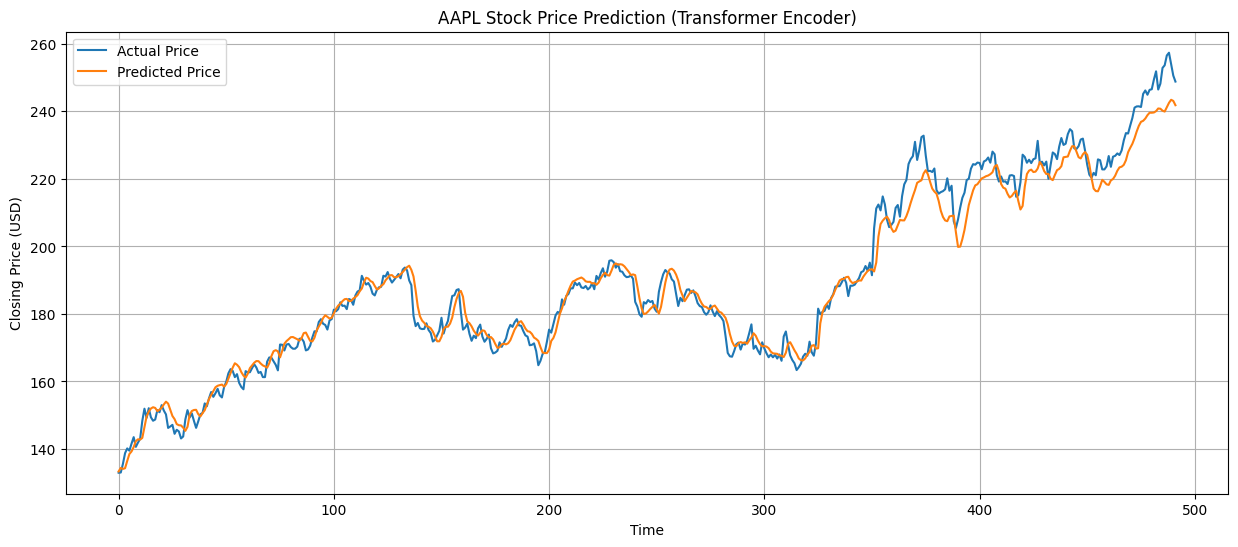

In [ ]:
plt.figure(figsize=(15, 6))

plt.plot(transformer_actual, label="Actual Price")
plt.plot(transformer_pred_actual, label="Predicted Price")

plt.title(f"{ticker} Stock Price Prediction (Transformer Encoder)")
plt.xlabel("Time")
plt.ylabel("Closing Price (USD)")

plt.legend()
plt.grid(True)

plt.show()